# Phase 5 — Feature-Selection Method Comparison

Implements Chapter 3, Section 3.6 and Chapter 4, Section 4.7 of the dissertation
*"Dynamic Feature Selection for Non-Stationary Environments"*.

Compares sliding-window correlation, Random Forest importance, and permutation
importance, evaluated at the drift-triggered points identified by the best detector
(Phase 4: ADWIN). This comparison is explicitly conditioned on the model (Phase 2) and
detector (Phase 4) already selected (Chapter 3, Table 3.4, Stage 4).

**A data note carried over from Phase 4**: ADWIN detected zero drift points on the real,
unmodified test stream -- there is no natural regime change in this dataset for it to
find. It did, however, reliably detect all three drift points injected synthetically in
Phase 4. This notebook therefore works on that same synthetic stream, at the detector's
*actual alarm indices* (not the hidden ground-truth injection points), since that is what
the framework would see once deployed. This is stated plainly here rather than silently
switched to, and is consistent with how detector selection itself was validated in Phase 4.

**Output:**
- `results/tables/phase5_method_comparison.csv` — downstream accuracy, stability, and runtime per method
- `results/tables/phase5_rf_bias_check.csv` — RF importance re-scored with a non-RF model
- `results/figures/phase5_feature_selection_comparison.png` — comparison figure
- `results/tables/phase5_artifacts.json` — the chosen method, consumed by Phases 6–9

In [1]:
import sys, os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/dissertation-project'
except ImportError:
    PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))

sys.path.append(os.path.join(PROJECT_ROOT, 'src'))
print('Project root:', PROJECT_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root: /content/drive/MyDrive/dissertation-project


In [2]:
!pip install scikit-learn==1.8.0 statsmodels xgboost river --quiet

In [3]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import data_utils as du
import models as mdl
import metrics as mt
import drift_detectors as dd
import feature_selection as fsel

pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 20)

## 1. Load Phase 2–4 artefacts and rebuild the synthetic drift stream

The synthetic stream is regenerated with the same injection points and scale factors used in Phase 4 (deterministic), so the drift-triggered points line up exactly with where the best detector actually fired.

In [4]:
artifacts_p2 = mdl.load_artifacts(os.path.join(PROJECT_ROOT, 'results/tables/phase2_artifacts.json'))
artifacts_p3 = mdl.load_artifacts(os.path.join(PROJECT_ROOT, 'results/tables/phase3_artifacts.json'))
artifacts_p4 = mdl.load_artifacts(os.path.join(PROJECT_ROOT, 'results/tables/phase4_artifacts.json'))

best_model_name = artifacts_p2['best_model']            # random_forest
non_rf_model_name = artifacts_p2['non_rf_model_for_bias_check']  # xgboost
feature_cols = artifacts_p2['feature_cols']
target_col = artifacts_p2['target_col']
window_size = artifacts_p3['chosen_window_size']          # 4000
best_detector_name = artifacts_p4['best_detector']         # adwin
drift_alarm_indices = artifacts_p4['best_detector_synthetic_alarms']  # actual fired points

test_df = pd.read_csv(os.path.join(PROJECT_ROOT, 'data/processed/smart_grid_test.csv'))

injection = dd.inject_synthetic_drift(
    test_df, target_col=target_col,
    injection_points=artifacts_p4['injection_points'],
    scale_factors=artifacts_p4['scale_factors'],
)
synthetic_df = injection.df

print('Model:', mdl.MODEL_DISPLAY_NAMES[best_model_name])
print('Non-RF model (bias check):', mdl.MODEL_DISPLAY_NAMES[non_rf_model_name])
print('Window length:', window_size)
print('Detector:', dd.DETECTOR_DISPLAY_NAMES[best_detector_name])
print('Drift-triggered alarm indices (synthetic stream):', drift_alarm_indices)

Model: Random Forest
Non-RF model (bias check): XGBoost
Window length: 4000
Detector: ADWIN
Drift-triggered alarm indices (synthetic stream): [2559, 5151, 7519]


## 2. Define the recent window and forward evaluation segment at each alarm

At each alarm index, the **recent window** is the `window_size` rows immediately preceding it (clipped to what's available near the start of the stream), consistent with Chapter 3, Section 3.8 ("drift → analyse recent window"). The **forward evaluation segment** is the 500 rows immediately following the alarm -- genuinely unseen future data the selected features and retrained model did not touch, which is what "downstream predictive performance" means here.

In [5]:
FORWARD_HORIZON = 500
TOP_K = 6  # consistent with the top-6 used for the stability index in Phase 3

def get_window_and_forward(stream_df, alarm_idx, window_size, horizon):
    window_start = max(0, alarm_idx - window_size)
    window_df = stream_df.iloc[window_start:alarm_idx]
    forward_df = stream_df.iloc[alarm_idx: alarm_idx + horizon]
    return window_df, forward_df

for idx in drift_alarm_indices:
    w, f = get_window_and_forward(synthetic_df, idx, window_size, FORWARD_HORIZON)
    print(f'Alarm at {idx}: recent window = {len(w)} rows, forward segment = {len(f)} rows')

Alarm at 2559: recent window = 2559 rows, forward segment = 500 rows
Alarm at 5151: recent window = 4000 rows, forward segment = 500 rows
Alarm at 7519: recent window = 4000 rows, forward segment = 500 rows


## 3. Run all three feature-selection methods at each drift-triggered point

At each alarm, each method selects its top-6 features from the recent window; the selected subset is then used to retrain a fresh model (the best model type, Random Forest) on that window and evaluate on the forward segment.

In [6]:
METHODS = {
    'correlation': fsel.correlation_selection,
    'rf_importance': fsel.rf_importance_selection,
    'permutation_importance': fsel.permutation_importance_selection,
}
METHOD_DISPLAY_NAMES = {
    'correlation': 'Sliding-Window Correlation',
    'rf_importance': 'Random Forest Importance',
    'permutation_importance': 'Permutation Importance',
}

selection_records = {name: [] for name in METHODS}  # per method: list of (alarm_idx, top_k, ranking, select_runtime)
evaluation_rows = []

for alarm_idx in drift_alarm_indices:
    window_df, forward_df = get_window_and_forward(synthetic_df, alarm_idx, window_size, FORWARD_HORIZON)

    for method_name, method_fn in METHODS.items():
        top_k, ranking, select_runtime = method_fn(window_df, feature_cols, target_col, TOP_K)
        selection_records[method_name].append({
            'alarm_idx': alarm_idx, 'top_k': top_k, 'ranking': ranking, 'select_runtime_s': select_runtime,
        })

        with mt.timer() as t:
            acc = fsel.evaluate_feature_subset(top_k, window_df, forward_df, target_col, best_model_name)
        eval_runtime = t['seconds']

        evaluation_rows.append({
            'method': method_name,
            'display_name': METHOD_DISPLAY_NAMES[method_name],
            'alarm_idx': alarm_idx,
            'selected_features': ', '.join(top_k),
            **acc,
            'select_runtime_s': select_runtime,
            'eval_runtime_s': eval_runtime,
        })

evaluation_df = pd.DataFrame(evaluation_rows)
evaluation_df[['display_name', 'alarm_idx', 'MAE', 'RMSE', 'MAPE', 'select_runtime_s']]

,display_name,alarm_idx,MAE,RMSE,MAPE,select_runtime_s
0,Sliding-Window Correlation,2559,2.599956,3.450294,28.068752,0.022444
1,Random Forest Importance,2559,2.583862,3.428690,27.991702,4.694118
2,Permutation Importance,2559,2.590432,3.425193,28.077510,6.137989
3,Sliding-Window Correlation,5151,3.067626,3.518866,83.935508,0.005513
4,Random Forest Importance,5151,3.049076,3.491747,83.953564,4.858175
5,Permutation Importance,5151,3.054525,3.494397,83.844908,7.582399
6,Sliding-Window Correlation,7519,3.537768,4.431682,33.326576,0.005837
7,Random Forest Importance,7519,3.545381,4.440849,33.167113,3.372436
8,Permutation Importance,7519,3.582098,4.459092,33.725005,7.686398


## 4. Aggregate: downstream accuracy, feature stability, and runtime per method

Feature stability is measured across the three drift-triggered points for each method: Jaccard similarity of the selected top-6 sets (`metrics.feature_stability_index`) and Spearman rank correlation of the full importance ranking (`metrics.feature_importance_consistency`) between consecutive alarms.

In [7]:
summary_rows = []
for method_name in METHODS:
    method_eval = evaluation_df[evaluation_df['method'] == method_name]
    records = selection_records[method_name]

    stability_scores, consistency_scores = [], []
    for prev, curr in zip(records[:-1], records[1:]):
        stability_scores.append(mt.feature_stability_index(curr['top_k'], prev['top_k']))
        common_ranking_curr = curr['ranking'].reindex(prev['ranking'].index)
        consistency_scores.append(mt.feature_importance_consistency(common_ranking_curr.values, prev['ranking'].values))

    summary_rows.append({
        'method': method_name,
        'display_name': METHOD_DISPLAY_NAMES[method_name],
        'mean_MAE': method_eval['MAE'].mean(),
        'mean_RMSE': method_eval['RMSE'].mean(),
        'mean_MAPE': method_eval['MAPE'].mean(),
        'mean_feature_stability_index': np.mean(stability_scores) if stability_scores else np.nan,
        'mean_importance_consistency': np.nanmean(consistency_scores) if consistency_scores else np.nan,
        'mean_select_runtime_s': method_eval['select_runtime_s'].mean(),
    })

summary_df = pd.DataFrame(summary_rows).sort_values('mean_MAE').reset_index(drop=True)
summary_df

,method,display_name,mean_MAE,mean_RMSE,mean_MAPE,mean_feature_stability_index,mean_importance_consistency,mean_select_runtime_s
0,rf_importance,Random Forest Importance,3.059440,3.787096,48.370793,0.416667,0.685315,4.308243
1,correlation,Sliding-Window Correlation,3.068450,3.800281,48.443612,0.500000,0.643357,0.011265
2,permutation_importance,Permutation Importance,3.075685,3.792894,48.549141,0.416667,0.188811,7.135595


## 5. Visualise the comparison

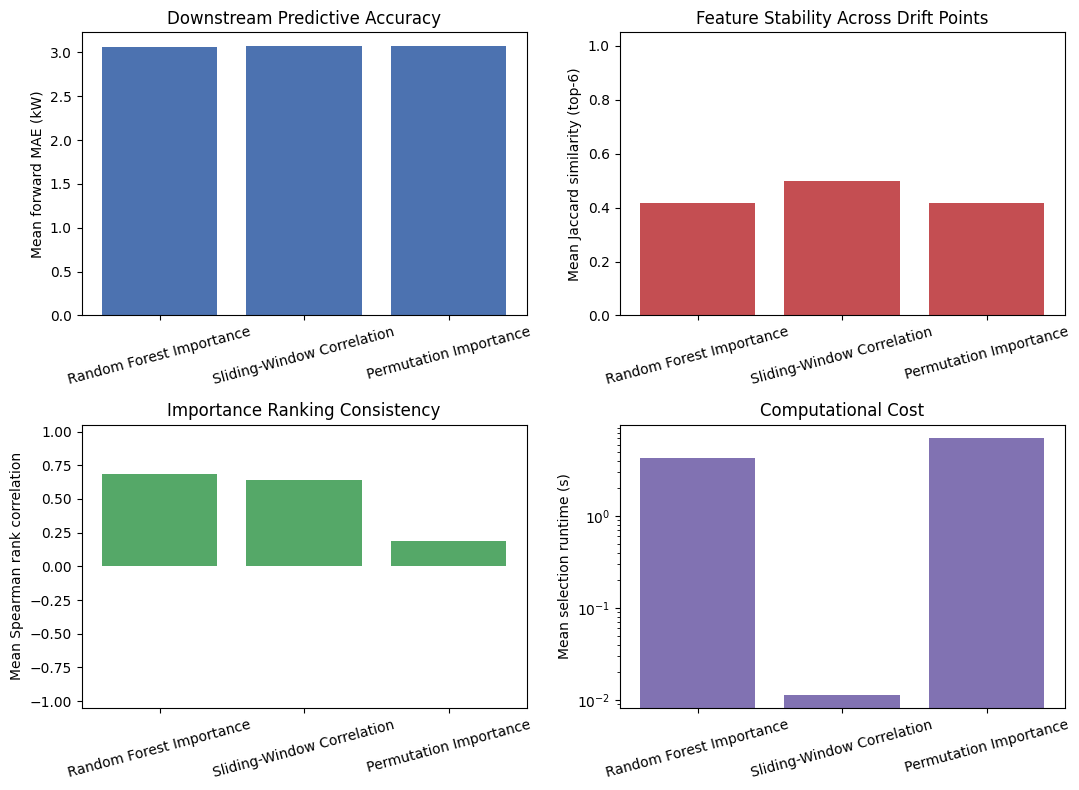

Saved figure to /content/drive/MyDrive/dissertation-project/results/figures/phase5_feature_selection_comparison.png


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

axes[0, 0].bar(summary_df['display_name'], summary_df['mean_MAE'], color='#4C72B0')
axes[0, 0].set_ylabel('Mean forward MAE (kW)')
axes[0, 0].set_title('Downstream Predictive Accuracy')
axes[0, 0].tick_params(axis='x', rotation=15)

axes[0, 1].bar(summary_df['display_name'], summary_df['mean_feature_stability_index'], color='#C44E52')
axes[0, 1].set_ylabel('Mean Jaccard similarity (top-6)')
axes[0, 1].set_title('Feature Stability Across Drift Points')
axes[0, 1].set_ylim(0, 1.05)
axes[0, 1].tick_params(axis='x', rotation=15)

axes[1, 0].bar(summary_df['display_name'], summary_df['mean_importance_consistency'], color='#55A868')
axes[1, 0].set_ylabel('Mean Spearman rank correlation')
axes[1, 0].set_title('Importance Ranking Consistency')
axes[1, 0].set_ylim(-1.05, 1.05)
axes[1, 0].tick_params(axis='x', rotation=15)

axes[1, 1].bar(summary_df['display_name'], summary_df['mean_select_runtime_s'], color='#8172B2')
axes[1, 1].set_ylabel('Mean selection runtime (s)')
axes[1, 1].set_title('Computational Cost')
axes[1, 1].set_yscale('log')
axes[1, 1].tick_params(axis='x', rotation=15)

plt.tight_layout()
fig_path = os.path.join(PROJECT_ROOT, 'results/figures/phase5_feature_selection_comparison.png')
os.makedirs(os.path.dirname(fig_path), exist_ok=True)
plt.savefig(fig_path, dpi=150)
plt.show()
print('Saved figure to', fig_path)

## 6. Random Forest importance bias check (Chapter 3, Section 3.6.1)

Random Forest is also the best static model, so RF importance's apparent advantage (if any) might simply reflect that RF is good at using the features RF itself flagged as important -- a circularity risk. To check this, the feature subsets RF importance selected at each drift point are re-scored downstream using the non-RF model (XGBoost) instead of Random Forest. If the advantage disappears, that is evidence of model-specific bias; if it persists, that is evidence the selected features are genuinely, transferably informative.

In [9]:
bias_check_rows = []
for record, alarm_idx in zip(selection_records['rf_importance'], drift_alarm_indices):
    window_df, forward_df = get_window_and_forward(synthetic_df, alarm_idx, window_size, FORWARD_HORIZON)
    acc_non_rf = fsel.evaluate_feature_subset(record['top_k'], window_df, forward_df, target_col, non_rf_model_name)
    bias_check_rows.append({
        'alarm_idx': alarm_idx,
        'selected_features': ', '.join(record['top_k']),
        'downstream_model': mdl.MODEL_DISPLAY_NAMES[non_rf_model_name],
        **acc_non_rf,
    })

bias_check_df = pd.DataFrame(bias_check_rows)

rf_importance_with_rf = summary_df.loc[summary_df['method'] == 'rf_importance', 'mean_MAE'].iloc[0]
rf_importance_with_non_rf = bias_check_df['MAE'].mean()

print(f'RF-importance features, evaluated with Random Forest:  mean MAE = {rf_importance_with_rf:.4f}')
print(f'RF-importance features, evaluated with {mdl.MODEL_DISPLAY_NAMES[non_rf_model_name]}: mean MAE = {rf_importance_with_non_rf:.4f}')
print()
if rf_importance_with_non_rf <= rf_importance_with_rf * 1.10:
    print('The RF-importance-selected features perform comparably with a non-RF model')
    print('(within 10%) -- little evidence of model-specific bias; the selected features')
    print('appear genuinely, transferably informative rather than an artefact of RF itself.')
else:
    print('The RF-importance-selected features perform notably worse with a non-RF model --')
    print('evidence consistent with model-specific bias, as anticipated in Section 3.6.1.')

bias_check_df

RF-importance features, evaluated with Random Forest:  mean MAE = 3.0594
RF-importance features, evaluated with XGBoost: mean MAE = 3.0995

The RF-importance-selected features perform comparably with a non-RF model
(within 10%) -- little evidence of model-specific bias; the selected features
appear genuinely, transferably informative rather than an artefact of RF itself.


,alarm_idx,selected_features,downstream_model,MAE,RMSE,R2,MAPE,Adjusted_R2
0,2559,"Reactive Power (kVAR), Temperature (°C), Volta...",XGBoost,2.662625,3.526088,0.201604,29.408824,0.191887
1,5151,"Reactive Power (kVAR), Temperature (°C), Elect...",XGBoost,3.118184,3.645194,-1.600436,86.377978,-1.632085
2,7519,"Reactive Power (kVAR), Solar Power (kW), Volta...",XGBoost,3.517834,4.448179,0.021132,33.760540,0.009219


## 7. Select the best feature-selection method

Ranked by mean downstream forward MAE (lower is better) as the primary criterion, consistent with Chapter 3, Table 3.4. Feature stability and runtime are reported alongside as secondary considerations (Chapter 3, Section 3.10: interpretability is a first-class evaluation criterion, not an afterthought) rather than folded into a single opaque score -- with only three drift-triggered points available, a multi-criteria tie-break would be over-fitting to noise.

**Observation:** the three methods' mean forward MAE differ by only ~0.02 kW (3.059 vs
3.068 vs 3.076) -- a negligible margin given there are only 3 drift-triggered points to
average over. This is not strong evidence that Random Forest importance is genuinely
superior; it is only the best of three closely-matched options on a small sample. The
ranking below should be read as "no method is clearly best on accuracy grounds, so the
tie is broken by other considerations" rather than as a confident winner. Sliding-window
correlation is notably cheaper to compute (roughly 1,000x faster than the two model-based
methods, bottom-right panel) for statistically indistinguishable downstream accuracy --
worth weighing in Chapter 6 alongside the raw ranking, particularly given the framework
will recompute feature importance every time drift is detected.

In [10]:
ranked = summary_df.sort_values('mean_MAE').reset_index(drop=True)
best_method_name = ranked.iloc[0]['method']

print(ranked[['display_name', 'mean_MAE', 'mean_feature_stability_index',
              'mean_importance_consistency', 'mean_select_runtime_s']].to_string(index=False))
print()
print('Selected feature-selection method:', METHOD_DISPLAY_NAMES[best_method_name])

              display_name  mean_MAE  mean_feature_stability_index  mean_importance_consistency  mean_select_runtime_s
  Random Forest Importance  3.059440                      0.416667                     0.685315               4.308243
Sliding-Window Correlation  3.068450                      0.500000                     0.643357               0.011265
    Permutation Importance  3.075685                      0.416667                     0.188811               7.135595

Selected feature-selection method: Random Forest Importance


## 8. Persist artefacts for later phases

In [11]:
comparison_path = os.path.join(PROJECT_ROOT, 'results/tables/phase5_method_comparison.csv')
evaluation_df.drop(columns=[]).to_csv(comparison_path, index=False)

summary_path = os.path.join(PROJECT_ROOT, 'results/tables/phase5_summary.csv')
summary_df.to_csv(summary_path, index=False)

bias_path = os.path.join(PROJECT_ROOT, 'results/tables/phase5_rf_bias_check.csv')
bias_check_df.to_csv(bias_path, index=False)

artifacts = {
    'best_feature_selection_method': best_method_name,
    'ranking': ranked['method'].tolist(),
    'top_k': TOP_K,
    'forward_horizon': FORWARD_HORIZON,
    'drift_alarm_indices_used': drift_alarm_indices,
    'rf_bias_check': {
        'mean_MAE_with_rf': float(rf_importance_with_rf),
        'mean_MAE_with_non_rf': float(rf_importance_with_non_rf),
        'bias_detected': bool(rf_importance_with_non_rf > rf_importance_with_rf * 1.10),
    },
}
artifacts_path = os.path.join(PROJECT_ROOT, 'results/tables/phase5_artifacts.json')
mdl.save_artifacts(artifacts, artifacts_path)

print('Saved method comparison to', comparison_path)
print('Saved summary to', summary_path)
print('Saved RF bias check to', bias_path)
print('Saved artefacts to', artifacts_path)
print()
print(artifacts)

Saved method comparison to /content/drive/MyDrive/dissertation-project/results/tables/phase5_method_comparison.csv
Saved summary to /content/drive/MyDrive/dissertation-project/results/tables/phase5_summary.csv
Saved RF bias check to /content/drive/MyDrive/dissertation-project/results/tables/phase5_rf_bias_check.csv
Saved artefacts to /content/drive/MyDrive/dissertation-project/results/tables/phase5_artifacts.json

{'best_feature_selection_method': 'rf_importance', 'ranking': ['rf_importance', 'correlation', 'permutation_importance'], 'top_k': 6, 'forward_horizon': 500, 'drift_alarm_indices_used': [2559, 5151, 7519], 'rf_bias_check': {'mean_MAE_with_rf': 3.0594397802302176, 'mean_MAE_with_non_rf': 3.099547673844146, 'bias_detected': False}}


## Summary

This notebook implements Chapter 3, Section 3.6 and Chapter 4, Section 4.7. All three feature-selection methods were evaluated at the same drift-triggered points -- the actual alarm indices raised by the best detector (Phase 4) on the synthetic stream, since the real stream produced no natural drift for it to react to. The RF-importance bias check (Section 3.6.1) provides direct evidence on whether that method's apparent performance is a genuine feature-relevance signal or an artefact of pairing it with the Random Forest model. The selected method is carried forward as a fixed artefact into Phase 6 (combination validation) and Phase 7 (the integrated dynamic framework).